# Nomes
### Breno Alves de Oliveira
### Henrique Lourenço

# **IIA007 (2sem2026) - Aula 14**
## *Atividade Prática - Preparação de Dados do Titanic*

----

## FATEC Ferraz de Vasconcelos
### Professora: Ana Rosa C. Tonão
#### Data:26/10/2026
----

## **Descrição dos Dados**

O conjunto de dados do Titanic contém características individuais dos passageiros e sobre a viagem.

Utilizando este conjunto de dados será possível criar um modelo de aprendizado de máquina que permitirá classificar os passageiros, entre os que sobreviveram e os que morreram naquela infeliz tragédia.

Cada passageiro é descrito pelas variáveis listadas abaixo:

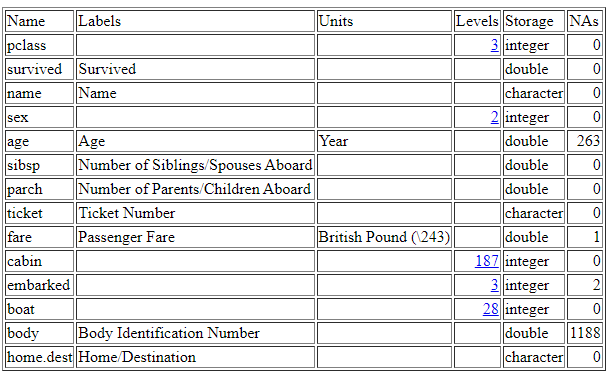

**pclass:** classe do passageiro (1=primeira, 2=segunda, 3=terceira)

**cabin:** número da cabine

**embarked:** local em que o passageiro embarcou (C=Cherbourg, Q=Queenstown, S=Southamption)

**sibsp:** número de irmãos/cônjuges a bordo

**parch:** número de pais/filhos a bordo

**boat:** bote salva-vidas

**home.dest:** cidade natal e cidade destino

***survived: sobreviveu (0=não, 1=sim)***

### **Fonte:**
https://hbiostat.org/data/repo/Ctitanic3.html


## **Importando as bibliotecas necessárias**

In [2]:
import pandas as pd

# **Pipeline de ML - Ingestão de Dados**

# **Parte I - Inspecionando os dados**

## **Carregando os dados de Titanic**

In [5]:
# Carregando os dados do arquivo titanic3.csv em um dataframe pandas
import pandas as pd

url = "https://hbiostat.org/data/repo/titanic3.csv"

df_titanic = pd.read_csv(url)

print(df_titanic.head())

   pclass  survived                                             name     sex  \
0       1         1                    Allen, Miss. Elisabeth Walton  female   
1       1         1                   Allison, Master. Hudson Trevor    male   
2       1         0                     Allison, Miss. Helen Loraine  female   
3       1         0             Allison, Mr. Hudson Joshua Creighton    male   
4       1         0  Allison, Mrs. Hudson J C (Bessie Waldo Daniels)  female   

     age  sibsp  parch  ticket      fare    cabin embarked boat   body  \
0  29.00      0      0   24160  211.3375       B5        S    2    NaN   
1   0.92      1      2  113781  151.5500  C22 C26        S   11    NaN   
2   2.00      1      2  113781  151.5500  C22 C26        S  NaN    NaN   
3  30.00      1      2  113781  151.5500  C22 C26        S  NaN  135.0   
4  25.00      1      2  113781  151.5500  C22 C26        S  NaN    NaN   

                         home.dest  
0                     St Louis, MO  


## **Inspecionando o conjunto de dados**

In [6]:
df_titanic

,pclass,survived,name,sex,age,sibsp,parch,ticket,fare,cabin,embarked,boat,body,home.dest
0,1,1,"Allen, Miss. Elisabeth Walton",female,29.00,0,0,24160,211.3375,B5,S,2,NaN,"St Louis, MO"
1,1,1,"Allison, Master. Hudson Trevor",male,0.92,1,2,113781,151.5500,C22 C26,S,11,NaN,"Montreal, PQ / Chesterville, ON"
2,1,0,"Allison, Miss. Helen Loraine",female,2.00,1,2,113781,151.5500,C22 C26,S,NaN,NaN,"Montreal, PQ / Chesterville, ON"
3,1,0,"Allison, Mr. Hudson Joshua Creighton",male,30.00,1,2,113781,151.5500,C22 C26,S,NaN,135.0,"Montreal, PQ / Chesterville, ON"
4,1,0,"Allison, Mrs. Hudson J C (Bessie Waldo Daniels)",female,25.00,1,2,113781,151.5500,C22 C26,S,NaN,NaN,"Montreal, PQ / Chesterville, ON"
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1304,3,0,"Zabour, Miss. Hileni",female,14.50,1,0,2665,14.4542,NaN,C,NaN,328.0,NaN
1305,3,0,"Zabour, Miss. Thamine",female,NaN,1,0,2665,14.4542,NaN,C,NaN,NaN,NaN
1306,3,0,"Zakarian, Mr. Mapriededer",male,26.50,0,0,2656,7.2250,NaN,C,NaN,304.0,NaN
1307,3,0,"Zakarian, Mr. Ortin",male,27.00,0,0,2670,7.2250,NaN,C,NaN,NaN,NaN


In [7]:
# Apresentando os nomes das colunas do conjunto de dados
df_titanic.columns

Index(['pclass', 'survived', 'name', 'sex', 'age', 'sibsp', 'parch', 'ticket',
       'fare', 'cabin', 'embarked', 'boat', 'body', 'home.dest'],
      dtype='str')

In [8]:
# Apresentando os datatypes das colunas do conjunto de dados
df_titanic.dtypes

pclass         int64
survived       int64
name             str
sex              str
age          float64
sibsp          int64
parch          int64
ticket           str
fare         float64
cabin            str
embarked         str
boat             str
body         float64
home.dest        str
dtype: object

In [9]:
# Usando o atributo .shape para apresentar o número de linhas e colunas
df_titanic.shape

(1309, 14)

In [10]:
# Estatísticas resumidas
# O método .describe informa os dados somente de colunas numéricas

df_titanic.describe()

,pclass,survived,age,sibsp,parch,fare,body
count,1309.000000,1309.000000,1046.000000,1309.000000,1309.000000,1308.000000,121.000000
mean,2.294882,0.381971,29.881138,0.498854,0.385027,33.295479,160.809917
std,0.837836,0.486055,14.413493,1.041658,0.865560,51.758668,97.696922
min,1.000000,0.000000,0.170000,0.000000,0.000000,0.000000,1.000000
25%,2.000000,0.000000,21.000000,0.000000,0.000000,7.895800,72.000000
50%,3.000000,0.000000,28.000000,0.000000,0.000000,14.454200,155.000000
75%,3.000000,1.000000,39.000000,1.000000,0.000000,31.275000,256.000000
max,3.000000,1.000000,80.000000,8.000000,9.000000,512.329200,328.000000


In [11]:
# Truncando para apresentar somente as duas primeiras colunas numéricas
df_titanic.describe().iloc[:, :2]

,pclass,survived
count,1309.000000,1309.000000
mean,2.294882,0.381971
std,0.837836,0.486055
min,1.000000,0.000000
25%,2.000000,0.000000
50%,3.000000,0.000000
75%,3.000000,1.000000
max,3.000000,1.000000


# **Parte II - Tratando os dados**

## **Limpeza dos dados**

In [12]:
# Apresentando o número de dados ausentes por coluna do conjunto de dados
df_titanic.isnull().sum()

pclass          0
survived        0
name            0
sex             0
age           263
sibsp           0
parch           0
ticket          0
fare            1
cabin        1014
embarked        2
boat          823
body         1188
home.dest     564
dtype: int64

### **Verifique quais necessitam de limpeza e/ou tratamento de informações:**
### *COLOQUE SEU CÓDIGO ABAIXO...*

In [18]:
df_titanic.value_counts(ascending=True, subset=['pclass'])

pclass
2         277
1         323
3         709
Name: count, dtype: int64

In [20]:
df_titanic.info()

<class 'pandas.DataFrame'>
RangeIndex: 1309 entries, 0 to 1308
Data columns (total 14 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   pclass     1309 non-null   int64  
 1   survived   1309 non-null   int64  
 2   name       1309 non-null   str    
 3   sex        1309 non-null   str    
 4   age        1046 non-null   float64
 5   sibsp      1309 non-null   int64  
 6   parch      1309 non-null   int64  
 7   ticket     1309 non-null   str    
 8   fare       1308 non-null   float64
 9   cabin      295 non-null    str    
 10  embarked   1307 non-null   str    
 11  boat       486 non-null    str    
 12  body       121 non-null    float64
 13  home.dest  745 non-null    str    
dtypes: float64(3), int64(4), str(7)
memory usage: 143.3 KB


In [19]:
df_titanic.value_counts(ascending=True, subset=['pclass', 'sex', 'age', 'survived'])

pclass  sex     age    survived
1       male    0.92   1            1
        female  2.00   0            1
                25.00  0            1
                63.00  1            1
        male    80.00  1            1
                                   ..
3       male    20.00  0           12
                28.00  0           13
                24.00  0           14
                22.00  0           16
                21.00  0           19
Name: count, Length: 423, dtype: int64

## **Feature Selection**

Decida quais colunas parecem ser importantes para responder à pergunta:


**O passageiro sobreviveu ou morreu?**



---


* Liste abaixo as colunas que em sua opinião deverão ser mantidas para uso no treinamento. Se possível inclua uma justificativa.

       *nome_coluna*

       *nome_coluna*

       *....*


In [21]:
# Identifique colunas que não apresentem nenhuma variação ou sinal, ou seja, que não estão fornecendo informações importantes para o modelo.

name = df_titanic.name
name.head(3)

0     Allen, Miss. Elisabeth Walton
1    Allison, Master. Hudson Trevor
2      Allison, Miss. Helen Loraine
Name: name, dtype: str

In [22]:
# Avaliando os valores das colunas tipo object.
df_titanic.embarked.value_counts(dropna=False)

embarked
S      914
C      270
Q      123
NaN      2
Name: count, dtype: int64

### **Continue a análise:**
### *COLOQUE SEU CÓDIGO ABAIXO...*

In [23]:
df_titanic.sex.value_counts(dropna=False)

sex
male      843
female    466
Name: count, dtype: int64

### **Elimine as colunas selecionadas acima:**
### *COMPLEMENTE E/OU AJUSTE O CÓDIGO ABAIXO...*

In [ ]:
# Elimine colunas deste tipo que você encontrar no conjunto de dados.
df_titanic = df_titanic.drop(
    columns=[
        "name",
        "ticket",
        "fare",
        "cabin",
        "embarked",
        "home.dest"
    ]
)

In [ ]:
df_titanic

### **Vazamento de informações:**

*O conjunto de dados do Titanic contém atributos que provocam vazamento de informações (leaky features).*

*Atributos que causam vazamento de informações são variáveis que contêm dados sobre o futuro ou o objetivo.*

### **Elimine as colunas selecionadas acima:**
### *COLOQUE SEU CÓDIGO ABAIXO...*

In [ ]:
# Elimine as colunas que podem gerar vazamento de informações
df_titanic = df_titanic.drop(
    columns=[
        "boat",
        "body"
    ]
)

In [ ]:
df_titanic

In [ ]:
df_titanic.dtypes

In [ ]:
df_titanic.columns

## **Label Encoding (*Rotulagem*)**

In [ ]:
# Avaliando os valores das colunas tipo object.
# As colunas tipo object podem conter categorias (dados tipo string com baixa cardinalidade), que são boas candidatas para label encoding (rotulagem).

df_titanic.sex.value_counts(dropna=False)

In [ ]:
# Crie colunas dummy a partir de colunas de string
df_titanic = pd.get_dummies(df_titanic)

In [ ]:
df_titanic.columns

In [ ]:
df_titanic

In [ ]:
# Remova colunas altamente correlacionadas para resolver o problema de multicolinearidade.
df_titanic = df_titanic.drop(columns="sex_male")

In [ ]:
## Se executar as de cima, não executar esta
# Crie colunas dummy a partir de colunas de string, realizando os dois passos acima com um só código
df_titanic = pd.get_dummies(df, drop_first=True)

In [ ]:
df_titanic

In [ ]:
df_titanic.columns

In [ ]:
df_titanic.isnull().sum()



## **Grave o DataFrame tratado com novo nome**

In [ ]:
# Gravando o dataframe tratado, em formato CSV)

df_titanic.to_csv('titanic_tratado.csv')

## ***FIM***